# Opiniómetro · Análisis exploratorio y experimentos

Este notebook acompaña al código de `src/`. **No reimplementa nada**: importa las mismas funciones
que usan el entrenamiento y la API, y las aplica sobre ejemplos para mostrar el efecto de cada decisión.

1. Análisis exploratorio de los datos
2. Pipeline de NLP paso a paso, con ejemplos antes y después
3. Resultados de los experimentos (validación cruzada)
4. Comparación de modelos en el conjunto de prueba
5. Análisis de errores

**Cómo ejecutarlo:** `docker compose --profile dev up notebook` y abrir http://localhost:8888.
Las secciones 3 a 5 leen `artifacts/`, así que primero hay que entrenar (`docker compose up` lo hace).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import LABELS, load_params
from src.data.prepare import clean
from src.nlp.preprocessing import TextPreprocessor, normalize, stopwords, strip_accents, tokenize

params = load_params()
KEEP = tuple(params["nlp"]["keep_words"])
EXTRA = tuple(params["nlp"]["extra_stopwords"])
COLORS = {"negativo": "#b91c1c", "neutro": "#a16207", "positivo": "#15803d"}
pd.set_option("display.max_colwidth", 120)

## 1. Análisis exploratorio

**Origen del dataset.** Reseñas sintéticas generadas por `src/data/generate.py` con semilla 42
(ver `data/README.md`). Se usan para que el ejemplo funcione sin Internet y se pueda repetir exactamente.
Los proyectos de los grupos deben usar datos reales.

In [2]:
raw = pd.read_csv(ROOT / params["data"]["raw_path"])
print(raw.shape)
raw.head()

(3045, 8)


,id,restaurante,ciudad,fecha,texto,estrellas,sentimiento,fenomeno
0,1,Punto Salteña,Sucre,2024-06-06,"Las salteñas estaban saladas, aunque la sajta de pollo estaba exquisita!",1,negativo,mixta
1,2,El Patio Vallegrandino,Santa Cruz,2025-11-30,"vine por recomendación de un amigo. es acogedor y tranquilo, las porciones son abundantes. la sajta de pollo estaba ...",4,positivo,negacion
2,3,La Cuchara de Barro,Cochabamba,2026-07-07,el mesero fue atento en todo momento. el PERSONAL es cordial y una experiencia excelente y volvería sin dudar,5,positivo,simple
3,4,Casa del Majadito,Cochabamba,2026-02-05,"Pedí por delivery, es acogedor y tranquilo. Nos encantó, nunca nos decepciona. El baño estaba sucio 👍",5,positivo,mixta
4,5,Casa del Majadito,La Paz,2025-04-22,fuimos en familia. la MEJOR dieta: pedir aquí y esperar sentado.,1,negativo,ironia


### Valores faltantes y duplicados

In [3]:
missing = raw.isna().sum().to_frame("faltantes")
missing["%"] = (missing["faltantes"] / len(raw) * 100).round(2)
print("Textos duplicados (sin contar vacíos):",
      raw.dropna(subset=["texto"]).duplicated(subset="texto").sum())
missing

Textos duplicados (sin contar vacíos): 54


,faltantes,%
id,0,0.00
restaurante,0,0.00
ciudad,92,3.02
fecha,0,0.00
texto,31,1.02
estrellas,0,0.00
sentimiento,0,0.00
fenomeno,0,0.00


- **`texto` vacío** → la fila no sirve para aprender: se elimina.
- **`ciudad` vacía** → el modelo no usa la ciudad: la fila se conserva.
- **Duplicados** → la misma reseña enviada dos veces. Si se quedan, una copia podría caer en entrenamiento
  y otra en prueba, y la métrica de prueba sería optimista. Se eliminan antes de dividir.

In [4]:
df, report = clean(raw)
report

{'raw_rows': 3045,
 'missing_values': {'ciudad': 92, 'texto': 31},
 'empty_texts_removed': 31,
 'duplicates_removed': 54,
 'clean_rows': 2960}

### Distribución de clases

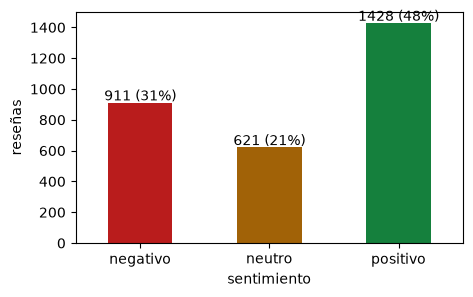

In [5]:
counts = df["sentimiento"].value_counts().reindex(LABELS)
ax = counts.plot.bar(color=[COLORS[l] for l in LABELS], rot=0, figsize=(5, 3))
ax.set_ylabel("reseñas")
for i, v in enumerate(counts):
    ax.text(i, v + 15, f"{v} ({v / len(df):.0%})", ha="center")
plt.show()

Las clases están **desbalanceadas** (casi la mitad son positivas). Consecuencias:

- Un modelo que siempre dice «positivo» acierta ~48 %: la **exactitud engaña**. Usamos **F1 macro**,
  que promedia el F1 de las tres clases con el mismo peso.
- La división entrenamiento/prueba es **estratificada**: mantiene estas proporciones en ambos lados.
- Probamos dos tratamientos en la búsqueda de hiperparámetros: `class_weight="balanced"` (regresión
  logística) y `fit_prior=False` (Naive Bayes). La validación cruzada decide si ayudan.

### Longitud de los textos

,count,mean,std,min,25%,50%,75%,max
sentimiento,,,,,,,,
negativo,911.0,14.2,6.5,2.0,9.0,13.0,18.0,42.0
neutro,621.0,12.6,5.0,2.0,9.0,12.0,16.0,29.0
positivo,1428.0,15.5,6.7,3.0,10.0,15.0,20.0,38.0


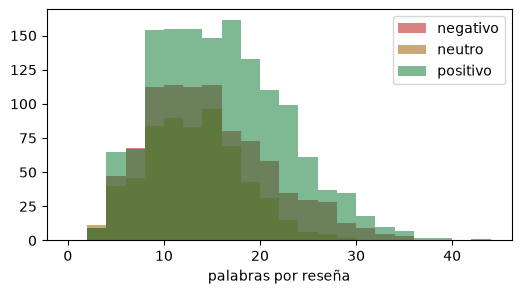

In [6]:
df["palabras"] = df["texto"].str.split().str.len()
display(df.groupby("sentimiento")["palabras"].describe().round(1))
fig, ax = plt.subplots(figsize=(6, 3))
for label in LABELS:
    ax.hist(df.loc[df["sentimiento"] == label, "palabras"], bins=range(0, 45, 2),
            alpha=0.55, label=label, color=COLORS[label])
ax.set_xlabel("palabras por reseña"); ax.legend(); plt.show()

Las reseñas son cortas (mediana ~13 palabras) y la longitud no separa las clases. Por eso no se agrega
como variable. El límite de la API (1000 caracteres) queda muy por encima del máximo observado.

### Palabras más frecuentes: con y sin stop words

In [7]:
from collections import Counter

def top_words(texts, stop=frozenset(), n=10):
    counter = Counter()
    for text in texts:
        counter.update(t for t in tokenize(normalize(text)) if strip_accents(t) not in stop)
    return [w for w, _ in counter.most_common(n)]

stop = stopwords("adjusted", KEEP, EXTRA)
pd.DataFrame({
    **{f"{l} (sin filtrar)": top_words(df.loc[df.sentimiento == l, "texto"]) for l in LABELS},
    **{f"{l} (sin stop words)": top_words(df.loc[df.sentimiento == l, "texto"], stop) for l in LABELS},
})

,negativo (sin filtrar),neutro (sin filtrar),positivo (sin filtrar),negativo (sin stop words),neutro (sin stop words),positivo (sin stop words)
0,el,el,el,no,ni,emojipositivo
1,estaba,de,de,emojinegativo,bien,bien
2,de,estaba,emojipositivo,pedido,pero,no
3,no,la,la,más,sin,muy
4,la,que,es,decepción,muy,sin
5,emojinegativo,es,en,porciones,darle,excelente
6,por,ni,estaba,mesero,oportunidad,experiencia
7,que,en,que,experiencia,fu,pedido
8,las,bien,bien,estrellas,fa,mejor
9,una,pero,fue,recomiendo,regular,nada


Sin filtrar, las tres clases comparten las mismas palabras («el», «y», «la», «estaba»): no informan nada.
Después del filtro aparecen palabras con carga: «no», «decepción», «sucio» en negativas; «normal»,
«regular», «ni» en neutras; «excelente», «recomiendo» en positivas.

### Estrellas frente a etiqueta

In [8]:
pd.crosstab(df["sentimiento"], df["estrellas"])

estrellas,1,2,3,4,5
sentimiento,,,,,
negativo,583,285,9,13,21
neutro,14,4,575,5,23
positivo,13,7,10,460,938


Hay reseñas con 5 estrellas etiquetadas como negativas (y al revés). Son **etiquetas ruidosas**:
errores de anotación que ningún modelo puede acertar y que ponen un techo a las métricas.
No las corregimos a mano para no tocar el conjunto de prueba; las reportamos en el análisis de errores.

## 2. Pipeline de NLP paso a paso

Todo está en `src/nlp/preprocessing.py`, dentro de la clase `TextPreprocessor`. Es un transformador de
scikit-learn, así que viaja **dentro** del pipeline guardado: la API ejecuta exactamente este código.

### 2.1 Normalización

In [9]:
examples = [
    "Q RICOOO el majadito!!! 😍😍",
    "Pésima atención 😡 esperamos 75 min. Fotos: https://fotos.ejemplo.bo/r/abc",
    "x fin algo bueno tb el api 👌 @doñatola #ComidaBoliviana",
    "La atención fue rápida",
]
pd.DataFrame({"antes": examples, "después": [normalize(e) for e in examples]})

,antes,después
0,Q RICOOO el majadito!!! 😍😍,que rico el majadito emojipositivo emojipositivo
1,Pésima atención 😡 esperamos 75 min. Fotos: https://fotos.ejemplo.bo/r/abc,pésima atención emojinegativo esperamos min fotos
2,x fin algo bueno tb el api 👌 @doñatola #ComidaBoliviana,por fin algo bueno también el api emojipositivo comidaboliviana
3,La atención fue rápida,la atención fue rápida


| Qué | Decisión | Por qué |
|---|---|---|
| Mayúsculas | a minúsculas | «Rico» y «rico» deben ser el mismo término |
| URLs y menciones | se eliminan | no expresan opinión |
| Emojis | se convierten en `emojipositivo`, `emojinegativo`, `emojiironia` | **sí** expresan opinión; borrarlos pierde información |
| Números | se eliminan | precios y minutos dependen del contexto («45» no es bueno ni malo) |
| Letras repetidas | «ricooo» → «rico» | en español nunca hay tres letras iguales seguidas |
| Jerga | «q» → «que», «x» → «por», «tb» → «también» | unifica variantes de la misma palabra |
| Puntuación | se elimina | TF-IDF trabaja con palabras |
| **Tildes** | **se conservan aquí** y se quitan al final | el lematizador de spaCy las necesita; al final se unifican «atención» y «atencion» |

### 2.2 Tokenización: casos difíciles del dominio

In [10]:
import spacy
nlp = spacy.load("es_core_news_sm")
hard = "¡¡Excelente!! el pique-macho 10/10 😋 #ComidaBoliviana q rico"
pd.DataFrame({
    "str.split()": pd.Series(hard.split()),
    "spaCy (texto crudo)": pd.Series([t.text for t in nlp(hard)]),
    "nuestro tokenize(normalize())": pd.Series(tokenize(normalize(hard))),
}).fillna("")

,str.split(),spaCy (texto crudo),nuestro tokenize(normalize())
0,¡¡Excelente!!,¡,excelente
1,el,¡,el
2,pique-macho,Excelente,pique
3,10/10,!,macho
4,😋,!,emojipositivo
5,#ComidaBoliviana,el,comidaboliviana
6,q,pique-macho,que
7,rico,10/10,rico
8,,😋,
9,,#,


- `split()` deja «¡¡Excelente!!» pegado a la puntuación: sería un término distinto de «excelente».
- spaCy separa bien la puntuación, pero conserva «10/10», «#» y el emoji como tokens sueltos.
- Como normalizamos antes, nos basta con separar por espacios. Además descartamos tokens de una letra
  («y», «a», «o»), que no aportan.
- «pique macho» queda en dos tokens: los **bigramas** permiten recuperarlo como unidad.

### 2.3 Stop words: la lista de spaCy borra el sentimiento

In [11]:
full = stopwords("spacy_full")
sentiment_words = ["no", "nunca", "nada", "bueno", "buena", "mejor", "peor", "bien", "mal", "muy", "sin", "pero"]
print("Están en la lista completa de spaCy:", [w for w in sentiment_words if w in full])

for text in ["No estaba bueno", "Estaba bueno", "Nunca más vuelvo"]:
    a = TextPreprocessor("stem", "spacy_full").explain(text)["final"]
    b = TextPreprocessor("stem", "adjusted", KEEP, EXTRA).explain(text)["final"]
    print(f"{text!r:22} lista completa → {a!s:28} ajustada → {b}")

Están en la lista completa de spaCy: ['no', 'nunca', 'nada', 'bueno', 'buena', 'mejor', 'peor', 'bien', 'mal', 'muy', 'sin', 'pero']


'No estaba bueno'      lista completa → []                           ajustada → ['no', 'buen']
'Estaba bueno'         lista completa → []                           ajustada → ['buen']
'Nunca más vuelvo'     lista completa → ['vuelv']                    ajustada → ['nunc', 'mas', 'vuelv']


Con la lista completa, «No estaba bueno» y «Estaba bueno» quedan **vacías**: el modelo no puede distinguirlas.
La lista **ajustada** (en `params.yaml`) devuelve a la lista de palabras útiles las negaciones, los
intensificadores y los adjetivos de valoración, y agrega palabras del dominio que aparecen en todas las
clases («restaurante», «local», «lugar»).

> Detalle de YAML: en `params.yaml` la palabra `"no"` va entre comillas. Sin comillas YAML la lee como el
> booleano `false` y el programa falla.

### 2.4 Stemming frente a lematización

In [12]:
words = "deliciosas atendieron atención recomiendo recomendable meseros salteñas rico fría".split()
stem = TextPreprocessor("stem", "adjusted", KEEP, EXTRA)
lemma = TextPreprocessor("lemma", "adjusted", KEEP, EXTRA)
pd.DataFrame({
    "palabra": words,
    "stem (Snowball)": [stem.explain(w)["roots"][0] if stem.explain(w)["roots"] else "" for w in words],
    "lema (spaCy, palabra sola)": [lemma.explain(w)["roots"][0] if lemma.explain(w)["roots"] else "" for w in words],
})

,palabra,stem (Snowball),"lema (spaCy, palabra sola)"
0,deliciosas,delici,deliciosa
1,atendieron,atend,atender
2,atención,atencion,atención
3,recomiendo,recom,recomeir
4,recomendable,recomend,recomendable
5,meseros,meser,meseros
6,salteñas,salteñ,salteña
7,rico,ric,rico
8,fría,fri,fría


In [13]:
sentence = "Los meseros nos atendieron rápido y las salteñas estaban riquísimas"
pd.DataFrame({
    "token": stem.explain(sentence)["without_stopwords"],
    "stem": stem.explain(sentence)["roots"],
    "lema (en contexto)": lemma.explain(sentence)["roots"],
})

,token,stem,lema (en contexto)
0,meseros,meser,mesero
1,atendieron,atend,atender
2,rápido,rap,rápido
3,salteñas,salteñ,salteña
4,riquísimas,riquisim,riquísima


- **Stemming** corta sufijos con reglas: es rápido y agresivo («recomiendo» y «recomendable» → `recom`/`recomend`),
  y produce raíces que no son palabras.
- **Lematización** busca la forma de diccionario usando la categoría gramatical: «atendieron» → «atender».
  Necesita el contexto de la oración, por eso se aplica a la oración completa antes de quitar stop words.
  El modelo pequeño `es_core_news_sm` se equivoca con algunas palabras («recomiendo» → «recomeir») y,
  con la palabra sola, deja «meseros» sin cambiar; dentro de la oración sí la resuelve («mesero»).
- No elegimos por intuición: **la validación cruzada compara ambos** (sección 3).

### 2.5 N-gramas y TF-IDF

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs = stem.transform(["No lo recomiendo, el silpancho estaba frío",
                       "Lo recomiendo, el silpancho estaba rico",
                       "El pique macho no estaba nada mal"])
for ngram in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=ngram).fit(docs)
    print(ngram, "→", list(vec.get_feature_names_out()))

(1, 1) → ['fri', 'mach', 'mal', 'nad', 'no', 'piqu', 'recom', 'ric', 'silpanch']
(1, 2) → ['fri', 'mach', 'mach no', 'mal', 'nad', 'nad mal', 'no', 'no nad', 'no recom', 'piqu', 'piqu mach', 'recom', 'recom silpanch', 'ric', 'silpanch', 'silpanch fri', 'silpanch ric']


Con unigramas, «no» y «recom» son términos independientes. Con bigramas aparecen `no recom`,
`nad mal` y `piqu mach`, que capturan la negación y los nombres de platos compuestos.

Parámetros de TF-IDF (en `params.yaml`):

In [15]:
params["tfidf"]

{'max_features': 5000, 'min_df': 2, 'max_df': 0.9, 'sublinear_tf': True}

- `max_features=5000`: tope de vocabulario; con bigramas el vocabulario real queda por debajo.
- `min_df=2`: un término que aparece en una sola reseña suele ser un error de tipeo; se ignora.
- `max_df=0.9`: un término presente en más del 90 % de las reseñas no distingue clases.
- `sublinear_tf=True`: usa 1 + log(tf); repetir «rico» cinco veces no pesa cinco veces más.

## 3. Experimentos: validación cruzada

`src/models/experiments.py` prueba **todas** las combinaciones de normalización × lista de stop words ×
n-gramas × modelo, cada una con su búsqueda de hiperparámetros (`GridSearchCV`, 5 particiones
estratificadas, **solo sobre entrenamiento**). La mejor configuración por F1 macro va a producción.

In [16]:
experiments = pd.read_csv(ROOT / "artifacts" / "experiments.csv")
experiments

,model,normalizer,stopword_list,ngram_range,hyperparameters,cv_f1_macro,cv_f1_macro_std,cv_accuracy
0,logistic_regression,stem,adjusted,1-2,"{""C"": 2.0, ""class_weight"": ""balanced""}",0.8747,0.0282,0.8902
1,logistic_regression,lemma,adjusted,1-2,"{""C"": 2.0, ""class_weight"": ""balanced""}",0.8743,0.0248,0.8902
2,logistic_regression,stem,adjusted,1-1,"{""C"": 5.0, ""class_weight"": null}",0.8641,0.0360,0.8813
3,logistic_regression,lemma,adjusted,1-1,"{""C"": 5.0, ""class_weight"": null}",0.8634,0.0308,0.8813
4,naive_bayes,stem,adjusted,1-2,"{""alpha"": 0.1, ""fit_prior"": false}",0.8574,0.0264,0.8758
5,naive_bayes,lemma,adjusted,1-2,"{""alpha"": 0.1, ""fit_prior"": false}",0.8568,0.0293,0.8754
6,logistic_regression,stem,spacy_full,1-2,"{""C"": 5.0, ""class_weight"": ""balanced""}",0.8537,0.0295,0.8729
7,logistic_regression,lemma,spacy_full,1-2,"{""C"": 5.0, ""class_weight"": null}",0.8489,0.0258,0.8725
8,logistic_regression,stem,spacy_full,1-1,"{""C"": 5.0, ""class_weight"": ""balanced""}",0.8468,0.0237,0.8645
9,logistic_regression,lemma,spacy_full,1-1,"{""C"": 5.0, ""class_weight"": null}",0.8423,0.0228,0.8657


In [17]:
models = experiments[experiments["model"] != "baseline"]
for factor in ["stopword_list", "ngram_range", "normalizer", "model"]:
    print(models.groupby(factor)["cv_f1_macro"].agg(["max", "mean"]).round(4), "\n")

                  max    mean
stopword_list                
adjusted       0.8747  0.8583
spacy_full     0.8537  0.8351 

                max    mean
ngram_range                
1-1          0.8641  0.8416
1-2          0.8747  0.8518 

               max    mean
normalizer                
lemma       0.8743  0.8468
stem        0.8747  0.8466 

                        max    mean
model                              
logistic_regression  0.8747  0.8585
naive_bayes          0.8574  0.8349 



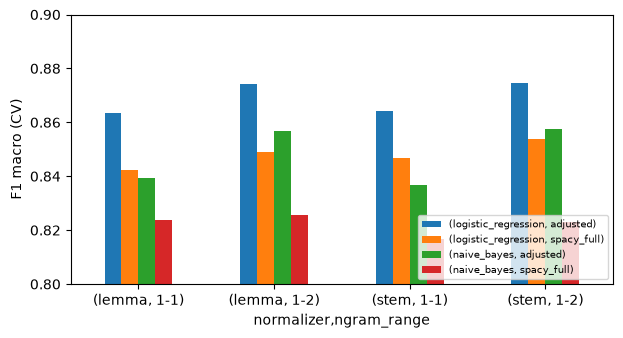

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.5))
pivot = models.pivot_table(index=["normalizer", "ngram_range"], columns=["model", "stopword_list"],
                           values="cv_f1_macro")
pivot.plot.bar(ax=ax, rot=0)
ax.set_ylim(0.8, 0.9); ax.set_ylabel("F1 macro (CV)")
ax.legend(fontsize=7, loc="lower right"); plt.show()

**Lectura de los resultados:**

1. **Stop words ajustadas** es la decisión que más pesa (~+2 puntos): conservar «no», «bueno», «mejor»
   devuelve información que la lista completa borraba.
2. **Bigramas** suman ~+1 punto: capturan «no recom», «nad mal».
3. **Stemming y lematización empatan** (diferencia menor que la desviación estándar entre particiones).
   A igualdad, stemming es más simple y rápido.
4. **Regresión logística** supera a Naive Bayes por ~1,7 puntos. Naive Bayes supone que las palabras son
   independientes; la regresión logística aprende un peso por término y maneja mejor términos correlacionados
   como «no» y «no recom».

## 4. Comparación en el conjunto de prueba

In [19]:
metrics = json.loads((ROOT / "artifacts" / "metrics.json").read_text())
pd.DataFrame([{
    "modelo": m["label"],
    "F1 macro CV": m["cv_f1_macro"],
    "exactitud prueba": m["test"]["accuracy"],
    "F1 macro prueba": m["test"]["f1_macro"],
    **{f"F1 {l}": m["test"]["per_class"][l]["f1"] for l in LABELS},
} for m in metrics["models"]]).set_index("modelo")

,F1 macro CV,exactitud prueba,F1 macro prueba,F1 negativo,F1 neutro,F1 positivo
modelo,,,,,,
Naive Bayes multinomial,0.8574,0.8885,0.8735,0.9066,0.7938,0.9201
Regresión logística,0.8747,0.8953,0.8796,0.8914,0.8125,0.9350
Línea base (clase más frecuente),0.2169,0.4831,0.2172,0.0000,0.0000,0.6515


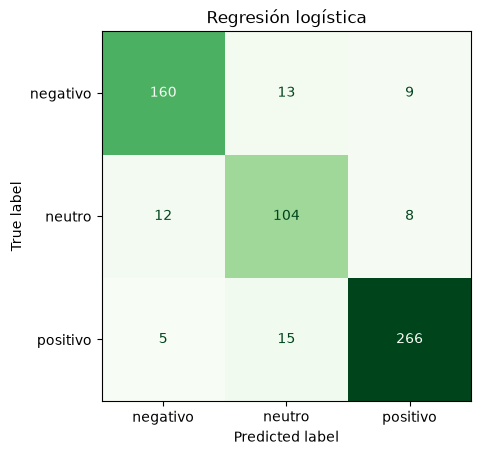

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

production = next(m for m in metrics["models"] if m["name"] == metrics["production"]["name"])
ConfusionMatrixDisplay(np.array(production["test"]["confusion_matrix"]), display_labels=LABELS) \
    .plot(cmap="Greens", colorbar=False)
plt.title(production["label"]); plt.show()

- Ambos modelos superan ampliamente a la línea base (F1 macro 0,22): **aportan valor**.
- La clase **neutra** es la más difícil (F1 ≈ 0,81): mezcla elogios y quejas en la misma reseña.
- Casi no hay confusión directa entre negativo y positivo; los errores pasan por «neutro».

## 5. Análisis de errores

In [21]:
errors = pd.read_csv(ROOT / "artifacts" / "errors.csv")
pd.DataFrame(metrics["accuracy_by_phenomenon"])

,fenomeno,n,accuracy
0,etiqueta_ruidosa,20,0.0000
1,mixta,169,0.7929
2,simple,274,0.9781
3,negacion,114,0.9912
4,ironia,15,1.0000


In [22]:
errors.sort_values("probabilidad", ascending=False).groupby("fenomeno").head(2)[
    ["texto", "real", "predicho", "probabilidad", "fenomeno"]]

,texto,real,predicho,probabilidad,fenomeno
21,El sabor es estandar. Habra que darle otra oportunidad.,negativo,neutro,0.9896,etiqueta_ruidosa
5,"Fuimos por el cumpleaños de mi mama y nos atendieron rapido. Una experiencia exclente, 10/10. 😍❤️",negativo,positivo,0.9677,etiqueta_ruidosa
37,"fuimos por el cumpleaños de mi mamá. el mesero fue atento en todo momento, pero regular, como cualquier otro.",positivo,neutro,0.8266,mixta
16,"El fricasé estaba súper salado, sin embargo el personal es cordial",negativo,neutro,0.7422,mixta
24,me cayo mal al estomago!!! #ComidaBoliviana,negativo,neutro,0.5019,simple
60,el pollo a la broaster tieneeee sabor de casa. el laping es lo mejor que probe en Santa Cruz.,positivo,neutro,0.4906,simple
17,"Cena de aniversario, el pedido tardó más de una hora. Nada recomendable.",negativo,neutro,0.4208,negacion


**Por qué falla el modelo:**

- **Etiquetas ruidosas (0 % de acierto).** El texto dice una cosa y la etiqueta otra. El modelo «acierta»
  según el texto y el error es del dato. Son el techo de cualquier modelo con estos datos.
- **Opiniones mixtas (~79 %).** «La sazón es excelente, aunque el baño estaba sucio»: TF-IDF suma
  evidencia positiva y negativa sin entender cuál pesa más para el autor.
- **Dobles negaciones.** «No estaban nada mal y no salimos con hambre» contiene tres negaciones;
  una bolsa de palabras no sabe que se anulan.
- **Ironía.** En estos datos sintéticos la ironía se acierta casi siempre porque sus frases se repiten entre
  entrenamiento y prueba. En datos reales cada ironía es distinta y suele ser el peor caso.

**Ideas de mejora:** más datos de reseñas mixtas, una etiqueta «mixta» explícita, trigramas para
negaciones dobles, o modelos que leen contexto (embeddings, transformers, fuera del alcance de este proyecto).